# Customer Behaviour in Streaming Services

Supervised and unsupervised learning on a streaming customer dataset: predicting monthly spend (regression) and churn (classification), and segmenting customers (clustering). Data is in `../data/Streaming.csv`.

In [12]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, davies_bouldin_score, silhouette_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

### Data Exploratory Analysis (DEA)
Let's explore the dataset and see how it looks like

In [13]:
# Let's read in our dataset and check it
df_original = pd.read_csv('../data/Streaming.csv')
df = df_original.copy()

In [14]:
df

,Customer_ID,Age,Gender,Subscription_Length,Region,Payment_Method,Support_Tickets_Raised,Satisfaction_Score,Discount_Offered,Last_Activity,Monthly_Spend,Churned
0,CUST000001,56.0,Male,54,South,PayPal,0,9.0,6.42,319,62.11,1
1,CUST000002,69.0,Female,21,East,Debit Card,1,2.0,13.77,166,37.27,1
2,CUST000003,46.0,Female,49,East,PayPal,3,8.0,19.91,207,61.82,0
3,CUST000004,32.0,Male,47,West,Debit Card,3,1.0,13.39,108,40.96,1
4,CUST000005,60.0,Male,6,East,Credit Card,2,NaN,13.18,65,45.97,0
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,CUST004996,24.0,Male,5,East,Debit Card,0,8.0,18.03,121,51.61,0
4996,CUST004997,66.0,Female,12,East,PayPal,3,5.0,5.84,192,36.32,0
4997,CUST004998,26.0,Female,1,East,Credit Card,2,8.0,6.76,354,42.07,1
4998,CUST004999,53.0,Female,44,South,Debit Card,1,10.0,5.95,31,60.09,0


In [15]:
# Check the count of missing values
df.isna().sum()

Customer_ID                 0
Age                       500
Gender                      0
Subscription_Length         0
Region                      0
Payment_Method              0
Support_Tickets_Raised      0
Satisfaction_Score        500
Discount_Offered            0
Last_Activity               0
Monthly_Spend               0
Churned                     0
dtype: int64

In [16]:
# Statistically describe the dataset
df.describe()

,Age,Subscription_Length,Support_Tickets_Raised,Satisfaction_Score,Discount_Offered,Last_Activity,Monthly_Spend,Churned
count,4500.000000,5000.000000,5000.000000,4500.00000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.582222,29.704400,2.037000,5.54600,12.458404,181.441400,46.619784,0.448000
std,14.969559,17.050336,1.422405,2.86929,4.325381,104.500951,9.522140,0.497338
min,18.000000,1.000000,0.000000,1.00000,5.000000,1.000000,-5.060000,0.000000
25%,31.000000,15.000000,1.000000,3.00000,8.700000,90.000000,39.897500,0.000000
50%,43.000000,29.000000,2.000000,6.00000,12.500000,182.000000,46.625000,0.000000
75%,56.000000,44.000000,3.000000,8.00000,16.190000,271.000000,53.210000,1.000000
max,69.000000,59.000000,9.000000,10.00000,20.000000,364.000000,137.310000,1.000000


In [17]:
# Check the data type of all columns 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             5000 non-null   object 
 1   Age                     4500 non-null   float64
 2   Gender                  5000 non-null   object 
 3   Subscription_Length     5000 non-null   int64  
 4   Region                  5000 non-null   object 
 5   Payment_Method          5000 non-null   object 
 6   Support_Tickets_Raised  5000 non-null   int64  
 7   Satisfaction_Score      4500 non-null   float64
 8   Discount_Offered        5000 non-null   float64
 9   Last_Activity           5000 non-null   int64  
 10  Monthly_Spend           5000 non-null   float64
 11  Churned                 5000 non-null   int64  
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB


### Detailed Analysis of Missing Data Patterns
The following function, `missing_pattern`, is designed to perform an exploratory data analysis (EDA) required before selecting an imputation method.

The purpose of the function is to test the hypothesis: Is the fact that a value is missing for a feature (e.g. Age, Satisfaction_Score) predictive of the target variable (Monthly_Spend)?

The analysis will help choose between two missing data mechanisms:

1. Missing Completely At Random (MCAR): The absence of a value is entirely random and non-related to the target variable.

2. Missing At Random (MAR): The absence of a value is systematic and related to the target variable.

Depending on the outcome, the appropriate imputation method will be used.

---
#### Function Breakdown

**Input**
- pandas DataFrame (`df`) containing the dataset
- feature column (`feature_col`) to analyse for missing values
- continuous target variable (`target_col`)

**Data Preparation**
- A binary indicator variable is created to represent missingness in the feature:
    - 1 if the feature value is missing
    - 0 if the feature value is present
- The target variable is split into two groups based on this indicator

**Group Comparison and testing**
- Descriptive statistics (count, mean, standard deviation, minimum, maximum) are computed for:
    - Observations with missing feature values
    - Observations with non-missing feature values
- A two-sample t-test is performed to compare the mean target values between the two groups

**Evaluation**
- If the p-value is below 0.05, missingness is considered likely predictive of the target variable
- If the p-value is above 0.05, missingness is unlikely to be predictive

In [18]:
def missing_pattern(df, feature_col, target_col):
    """
    Analyses if the missingness in a feature column is predictive of a continuous target variable.

    Args:
        df (pd.DataFrame): The input data DataFrame.
        feature_col (str): The name of the column to check for missing values.
        target_col (str): The name of the continuous target column (e.g., 'Monthly Spend').

    Returns:
        dict: A dictionary containing the descriptive statistics and T-test results.
    """

    result = {}
    
    if feature_col not in df.columns or target_col not in df.columns:
        print("Error: One or both columns not found in the DataFrame.")
        return None

    # --------------------------------------------------------
    # Create a new column with values 1 if missing value in feature_col or 0 if not
    analysis_df = df.copy()
    analysis_df['is_missing'] = analysis_df[feature_col].isna()
    analysis_df['is_missing'] = analysis_df['is_missing'].astype(int)

    # Separate the target values into two groups
    non_missing_group = analysis_df[analysis_df['is_missing'] == 0][target_col] # target group of non-missing values in festure_col
    missing_group = analysis_df[analysis_df['is_missing'] == 1][target_col] # target group of missing values in feature_col

    # Check if there are missing values to analyze
    if missing_group.empty:
        print(f"No missing values found in the feature: {feature_col}. Analysis complete.")
        return None
        
    # --------------------------------------------------------
    # Compute statistics on different groups
    group = analysis_df.groupby('is_missing')[target_col]
    statistics = group.agg(['count', 'mean', 'std', 'min', 'max']).rename(index={0: 'non_missing', 1: 'missing'})
    
    # Perform a Two-Sample T-test
    # We use equal_var=False if we don't assume equal variances (Welch's T-test, safer)
    t_stat, p_value = stats.ttest_ind(non_missing_group, missing_group, equal_var=False)

    # --------------------------------------------------------
    # Compute the results
    results = {
        'Feature_Checked': feature_col,
        'Target_Variable': target_col,
        'Statistics': statistics,
        'T-Test_Results': {'T_Statistic': t_stat, 'P_Value': p_value}
    }

    print("Analysis in progress")
    print(f"--- Missingness Analysis for '{feature_col}' vs. '{target_col}' ---")
    print(f"\nStatistics {target_col}:")
    print(statistics)
    
    print("\nStatistical Test (Two-Sample T-test):")
    print(f"T-Statistic: {t_stat:.4f}")
    print(f"P-Value:     {p_value:.4f}")
    
    # --------------------------------------------------------
    # Interpretation of the results
    alpha = 0.05
    if p_value < alpha:
        print(f"\nConclusion (at alpha={alpha}): Reject the Null Hypothesis.")
        print(f"The mean '{target_col}' is SIGNIFICANTLY DIFFERENT between customers with missing and non-missing '{feature_col}'.\n")
        
    else:
        print(f"\nConclusion (at alpha={alpha}): Fail to Reject the Null Hypothesis.")
        print(f"The mean '{target_col}' is NOT statistically different. The missingness is likely not predictive.\n")
        
    return results

In [19]:
Age_missing = missing_pattern(df, 'Age', 'Monthly_Spend')
Satisfaction_Score_missing = missing_pattern(df, 'Satisfaction_Score', 'Monthly_Spend')

Analysis in progress
--- Missingness Analysis for 'Age' vs. 'Monthly_Spend' ---

Statistics Monthly_Spend:
             count      mean       std    min     max
is_missing                                           
non_missing   4500  46.59368  9.517543  -5.06  137.31
missing        500  46.85472  9.569772  21.77   70.00

Statistical Test (Two-Sample T-test):
T-Statistic: -0.5790
P-Value:     0.5628

Conclusion (at alpha=0.05): Fail to Reject the Null Hypothesis.
The mean 'Monthly_Spend' is NOT statistically different. The missingness is likely not predictive.

Analysis in progress
--- Missingness Analysis for 'Satisfaction_Score' vs. 'Monthly_Spend' ---

Statistics Monthly_Spend:
             count       mean       std    min     max
is_missing                                            
non_missing   4500  46.566378  9.562855  -5.06  137.31
missing        500  47.100440  9.142744  24.85   67.98

Statistical Test (Two-Sample T-test):
T-Statistic: -1.2334
P-Value:     0.2179

Conclusio

By analysing the statistics of Monthly_Spend, there is a least one negtive value. This is confirmed by the below output where we have 2 rows with negative Monthly_Spend.
This is an issue for the model we have to develop, since these values will introduce outliers. To deal with this, we have two options:
1. Drop the negative rows: since it is only 2 rows over 5,000 rows, the lost will be 0.04% and let the model learn only true patterns.
2. Cap the negative values to 0: we will keep all rows for the learning process but alter the natural distribution of the target variable and introduce also articifial values (0) for the model to learn. 

we only have these two options because attempting an imputation for the target value is highly not advised. This would introduce artificial values in the target variable and therefore bias the learning process.

Since the number of rows having the negative valued in really small compared the dataset's size, dropping the 2 rows is the safest option.

In [20]:
df[df['Monthly_Spend']<0]

,Customer_ID,Age,Gender,Subscription_Length,Region,Payment_Method,Support_Tickets_Raised,Satisfaction_Score,Discount_Offered,Last_Activity,Monthly_Spend,Churned
1353,CUST001354,18.0,Male,33,South,PayPal,2,4.0,7.18,205,-5.06,0
3929,CUST003930,66.0,Female,10,East,Debit Card,1,2.0,14.65,140,-3.52,1


### Using Kernel Density Estimate to impute the mising values
Since we established that data missing is completely random, our imputation piority now is to preserve the natural distribution (shape and variance) of the variables.
The two rows with the negative values will be dropped during the imputation process

In [21]:
def kde_imputation(df, columns_to_impute):
    """
    Performs Kernel Density Estimation (KDE) imputation on specified columns.

    Args:
        df: The input data DataFrame.
        columns_to_impute: A list of numerical column names to be imputed.

    Returns:
        df_imputed: The DataFrame with the specified columns imputed.
    """
    df_imputed = df.copy()

    for col in columns_to_impute:
        # Check if the column is numerical and has missing values
        if df_imputed[col].dtype in ['int64', 'float64'] and df_imputed[col].isna().any():
            
            # Identify non-missing data and reshape for KDE
            observed_data = df_imputed[col].dropna().values.reshape(-1, 1)
            
            # Identify indices of missing data
            missing_indices = df_imputed[df_imputed[col].isna()].index
            n_missing = len(missing_indices)

            # Fit the KDE Model. The bandwidth is selected automatically to balance bias and variance
            try:
                kde = KernelDensity(kernel='gaussian', bandwidth='scott')
                kde.fit(observed_data)
            except ValueError as e:
                print(f"Skipping KDE for {col}: Could not fit model. Error: {e}")
                continue

            # Create new samples from the fitted distribution
            new_samples = kde.sample(n_samples=n_missing, random_state=42)
            
            # Flatten the samples for insertion
            new_samples = new_samples.flatten()

            # Impute the missing values with values from the distribution
            df_imputed.loc[missing_indices, col] = new_samples
            
            print(f"Successfully imputed {n_missing} missing values in column '{col}' using KDE.")

        elif col not in df_imputed.columns:
             print(f"Warning: Column '{col}' not found in the DataFrame.")
        elif not df_imputed[col].isnull().any():
             print(f"No missing values in column '{col}'. Skipping imputation.")

    # Convert the age column into integer
    df_imputed['Age'] = df_imputed['Age'].round().astype(int)
    # Keeps only rows with positive value of Monthly_Spend
    df_imputed = df_imputed[df_imputed['Monthly_Spend'] >=0].copy()
    
    return df_imputed

In [22]:
df = kde_imputation(df, ['Age', 'Satisfaction_Score'])

Successfully imputed 500 missing values in column 'Age' using KDE.
Successfully imputed 500 missing values in column 'Satisfaction_Score' using KDE.


#### Let's explore the correletion between the Monthly_Spend and other numeric columns
We can notice, Satisfaction_Score has the highest correletion followed by Subscription_Length

In [23]:
# Create a correletion matrix to see how the different features are correleted to Monthly_Spend
corr_matrix = df.corr(numeric_only=True)
corr_matrix["Monthly_Spend"].sort_values(ascending=False)

Monthly_Spend             1.000000
Satisfaction_Score        0.686880
Subscription_Length       0.548896
Discount_Offered          0.216481
Last_Activity             0.004759
Age                       0.003388
Support_Tickets_Raised   -0.162696
Churned                  -0.449944
Name: Monthly_Spend, dtype: float64

### Regression Models
`RegressionExperiment` class
This class is a complete worklow to compare multiple regression models to predict monthly spend and evaluate their performance.

---
### Initialisation

**Purpose:** Initialise configuration parameters and placeholders for running multiple regression experiments

**Parameters:**
- `df` (**pd.DataFrame**): Cleaned dataset used for regression
- `target_col` (**str**):  Target variable

**Sets:**
- self.target_col: Target variable name
- self.results: Dictionary to store model performance metrics

---
### Data Preparation

**Purpose:** Prepare input features and target variable for regression

**Process:**
- Separates features and target variable
- Splits the data into training (80%) and test (20%) sets
- Applies feature scaling where required
- Encodes categorical variables using one-hot encoding when necessary

**Output:**
x_train, x_test: Training and test feature matrices
y_train, y_test: Training and test target vectors

---
### Linear Regression

**Purpose:** Train and evaluate linear regression model

**Process:**
- Fits a linear regression model using a single numerical feature
- Generates predictions on the test set
- Computes regression metrics
- Visualises the fitted regression line when applicable

**Output:**
- Stored predictions and evaluation metrics for linear regression

---
### Polynomial Regression

**Purpose:** Capture non-linear relationships between input features and the target variable

**Process:**
- Applies polynomial feature expansion
- Trains a linear regression model on the transformed features
- Evaluates predictions on the test set
- Visualises the fitted polynomial curve

**Output:**
- Stored predictions and evaluation metrics for polynomial regression

---
### Random Forest Regression

**Process:**
- Combines numerical and encoded categorical features
- Trains a random forest regressor within a preprocessing pipeline
- Generates predictions on the test set

**Output:**
- Stored predictions and evaluation metrics for random forest regression

---
### Neural Network Regression

**Process:**
- Scales numerical features using min–max normalisation
- Encodes categorical features using one-hot encoding
- Trains a configurable neural network with dropout and early stopping
- Records training history for later analysis

**Output:**
- Stored predictions, evaluation metrics, and training history for the neural network

---
### Evaluation

**Metrics:**
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination (R²)

**Output:**
- Summary of model performance across all regression approaches

In [15]:
class RegressionExperiment:
    def __init__(self, df, target_col):
        self.df = df
        self.target = target_col
        self.results = {}

    # -----------------------------------------------------------
    # Feature preparation method
    def prepare_feature(self, feature_col):
        # reshape x into 2D numpy array if input is single feature
        if isinstance(feature_col, str):
            x = self.df[feature_col].to_numpy().reshape(-1, 1)
        else:
            x = self.df[feature_col]
        
        y = self.df[self.target]
        
        # Split dataset into training and checking tests
        # Test set will be 20% of the dataset
        self.x_train, self.x_test, self.y_train, self.y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

        # Apply standarisation by scaling the input feature
        self.scale = StandardScaler()
        self.scale.fit(self.x_train)
        self.x_train_scaled = self.scale.transform(self.x_train)
        self.x_test_scaled = self.scale.transform(self.x_test)
        
    # -----------------------------------------------------------
    # Linear regression method
    def linear_regression(self, feature_col, plot=True):
        # Create the linear model and train it over the scaled training set
        model = LinearRegression()
        model.fit(self.x_train_scaled, self.y_train)
        
        # Perform prediction on the test set and compute evaluation metrics
        y_pred = model.predict(self.x_test_scaled)
        metrics = self.evaluate(self.y_test ,y_pred)

        # Store the performance results
        self.results[f"Linear_{feature_col}"] = metrics

        # We only plot when having single feature
        if plot and isinstance(feature_col, str):
            self.plot_fit(model, feature_col)

        return metrics
        
    # -----------------------------------------------------------
    # Polynomial regression method
    def polynomial_regression(self, feature_col, poly_degree, plot=True):
        # create a polynomial regression model of degree defined by poly_degree
        poly = PolynomialFeatures(degree = poly_degree, include_bias = False)
        
        x_train_poly = poly.fit_transform(self.x_train_scaled)
        x_test_poly = poly.transform(self.x_test_scaled)

        model = LinearRegression()
        model.fit(x_train_poly, self.y_train)
        
        # Perform prediction on the test set and compute evaluation metrics
        y_pred = model.predict(x_test_poly)
        metrics = self.evaluate(self.y_test, y_pred)

        # Store the performance results
        self.results[f"Poly{poly_degree}_{feature_col}"] = metrics

        # We only plot when having single feature
        if plot and isinstance(feature_col, str):
            self.plot_fit(model, feature_col, poly, poly_degree)
                
        return metrics

    # -----------------------------------------------------------
    # Define random forest regressor method
    def random_forest(self, num_features, cat_features, n_trees=200):
        # Define input features as concatenation of both numerical and categorical features
        x = self.df[num_features + cat_features]
        y = self.df[self.target]
    
        # Preprocessing: Transform only categorical columns using One Hot Enoder
        # ColumnTransformer applies One Hot Encoder on cat_featurs, lets num_features untouched and concatenates the output for us
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', 'passthrough', num_features),
                ('cat', OneHotEncoder(drop='first',  handle_unknown='ignore'), cat_features)])
    
        # Define Random forest regressor
        # n_estimator defines the number of trees 
        # random_state is set for reproductivity
        random_regressor = RandomForestRegressor(n_estimators=n_trees, random_state=1)
    
        # Now let's define the full pipeline
        model = Pipeline(steps=[('preprocessing', preprocessor), ('regressor', random_regressor)])
    
        # Split training and testing set
        x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)
    
        # Train the model
        model.fit(x_train, y_train)
    
        # Make predictions and compute evaluation
        y_pred = model.predict(x_test)
        metrics = self.evaluate(y_test, y_pred)

        # Store the prediction and test set for later plotting
        self.rf_y_pred = y_pred
        self.rf_y_test = y_test
    
        # Store the performance results
        self.results["Random_Forest(all features)"] = metrics
    
        return metrics

    # -----------------------------------------------------------
    # Define artificial neural network method
    def neural_network(self, num_features, cat_features, epochs=200, dropout_rate=0.2,
                      n_layers=2, hidden_units=64, learning_rate=0.001):
        # Define input features as concatenation of both numerical and categorical features
        x_num = self.df[num_features] 
        x_cat = self.df[cat_features]
        y = self.df[self.target]

        # Encode categorical variables
        encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
        x_cat_encoded = encoder.fit_transform(x_cat)

        # Concatenate numerical and categorical features
        x = np.hstack([x_num.values, x_cat_encoded])
        
        # Prepare the data and proceed to scaling
        x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)
        
        scale = MinMaxScaler()
        scale.fit(x_train)
        x_train_scaled = scale.transform(x_train)
        x_test_scaled = scale.transform(x_test)

        # Build the neural network model
        model = Sequential()
        model.add(Dense(units = hidden_units, input_dim = x_train_scaled.shape[1], activation = 'relu'))
        model.add(Dropout(dropout_rate))
        
        for layer in range(n_layers-1):
            model.add(Dense(units = hidden_units, activation = 'relu'))
            model.add(Dropout(dropout_rate))
        
        model.add(Dense(units = 1, activation = 'linear'))
        model.summary()
        
        adam_optimizer = Adam(learning_rate)
        
        model.compile(optimizer=adam_optimizer, loss='mean_squared_error', metrics=['mean_squared_error'])
        early_stopping = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

        # Train the model
        history = model.fit(x = x_train_scaled, y = y_train, batch_size = None, epochs = epochs,
                   verbose = 'auto', validation_split = 0.1, callbacks = [early_stopping])

        # Perform prediction and evaluate performance
        y_pred = model.predict(x_test_scaled)
        metrics = self.evaluate(y_test, y_pred)

        # Store the prediction and test set for later plotting
        self.nn_y_pred = y_pred
        self.nn_y_test = y_test

        # Store results
        self.results[f"ANN_drop{dropout_rate}_learning{learning_rate}_layer{n_layers}_units{hidden_units}"] = metrics

        # Convert history to dataframe and save it for plot
        self.history_df = pd.DataFrame(history.history)

        return metrics

    # -----------------------------------------------------------
    # Define how to evaluate the metrics
    def evaluate(self, y_true, y_pred):
        return {
            'Mean Absolute Error': mean_absolute_error(y_true, y_pred),
           'Mean Squared Error': mean_squared_error(y_true, y_pred),
           'Root Mean Squared Error': np.sqrt(mean_squared_error(y_true, y_pred)),
           'Coefficient of Determination (R2)': r2_score(y_true, y_pred)
        }
        
    # -----------------------------------------------------------
    # Define plotting method. this method applies only to single input feature
    def plot_fit(self, model, feature_col, poly=None, poly_degree=None):
        # Generate random inputs and predict the output
        x_fit = np.linspace(self.df[feature_col].min(), self.df[feature_col].max(), 300).reshape(-1, 1)
        x_fit_scaled = self.scale.transform(x_fit) # Scale the random inputs before passing it to the model
        
        if poly is None:
            # Perform prediction on the random inputs
            y_fit = model.predict(x_fit_scaled)
    
            # Plot our model
            pred_plot = sns.scatterplot(data = self.df, x = feature_col, y = self.target) 
            plt.plot(x_fit, y_fit)
        
            # save the figure dynamically depending on the input feature_col
            plt.title(f"Linear Regression: {self.target} vs {feature_col}")
            plt.tight_layout()
            filename = f"{feature_col}_linear_plot.png"
            pred_plot.figure.savefig(filename)
            plt.show()

        else:
            # Map the feature to polynomial degree
            x_fit_scaled_poly = poly.transform(x_fit_scaled)
            y_fit_poly = model.predict(x_fit_scaled_poly) # Perform prediction on the random inputs
        
            # Plot our model
            poly_plot = sns.scatterplot(data = self.df, x = feature_col, y = self.target) 
            plt.plot(x_fit, y_fit_poly)
            
            # save the figure dynamically depending on the input feature_col
            plt.title(f"Polynomial Regression: {self.target} vs {feature_col}")
            plt.tight_layout()
            filename = f"{feature_col}_poly{poly_degree}_plot.png"
            poly_plot.figure.savefig(filename)
            plt.show()
    
    # -----------------------------------------------------------
    # Define comparison plot method between random forest and neural network
    # Plot predicted vs real monthly_spend
    def plot_predicted(self):
        try:
            # Prediction line to fit all values
            min_val = min(self.nn_y_test.min(), self.rf_y_test.min(), self.nn_y_pred.min(), self.rf_y_pred.min())
            max_val = max(self.nn_y_test.max(), self.rf_y_test.max(), self.nn_y_pred.max(), self.rf_y_pred.max())

            # Adding a small space so that points are not cut off by the borders
            small_space = (max_val - min_val) * 0.02
            limit_min = min_val - small_space
            limit_max = max_val - small_space
            
            # Plot the ideal prediction line
            plt.figure(figsize=(8,8))
            plt.plot([limit_min, limit_max], [limit_min, limit_max], linestyle='--', label='Ideal prediction (y=x)')

            # Set plot limits to fit the data
            plt.xlim(limit_min, limit_max)
            plt.ylim(limit_min, limit_max)
            
            # Plot neural network prediction
            plt.scatter(self.nn_y_test, self.nn_y_pred, alpha=0.6, label='Neural Network', marker='o', color='mediumblue')

            # Plot random forest prediction
            plt.scatter(self.rf_y_test, self.rf_y_pred, alpha=0.6, label='Random Forest', marker='x', color='darkorange')

            
            plt.xlabel("Real Monthly Spend")
            plt.ylabel("Predicted Monthly Spend")
            plt.title("Predicted vs Real Monthly Spend (Neural Network vs Random Forest)")
            plt.legend()
            plt.tight_layout()
            plt.savefig('./comparison_plot.png')
            plt.show()

        except:
            raise ValueError("Run Neural Network and Random Forest before plotting")
            
            

#### Simple Linear Regression and Single Polynomial (degree 2) Regression models

The following features are chosen for single feature models based on the correlation result:
1. Satisfaction_Score
2. Subscription_Length
3. Discount_Offered

For multi-feature models, all the numerical features of the dataset are used.

The below code does the following:
1. creates a `RegressionExperiment` instance
2. performs both simple linear regression on each individual chosen feature and multi-feature regression as well
3. repeats the same process for polynomial regression.

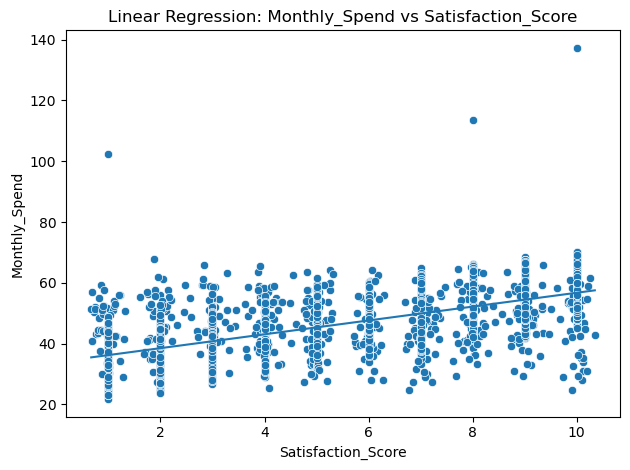

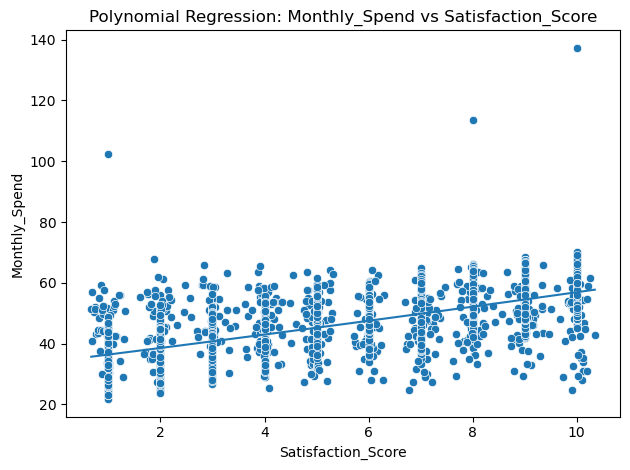

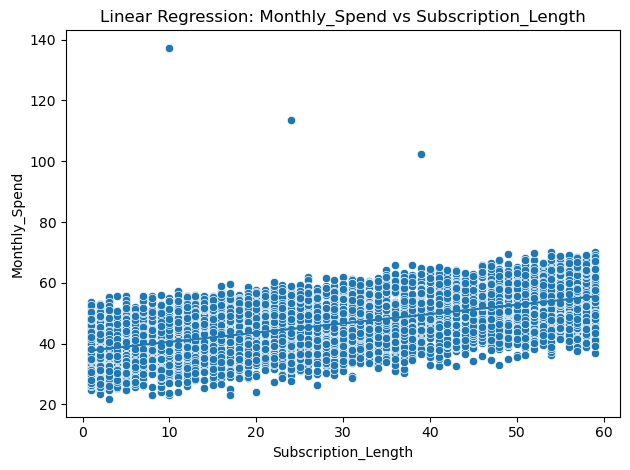

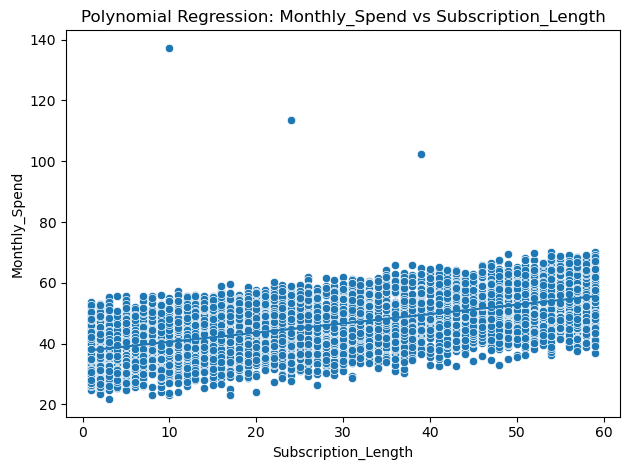

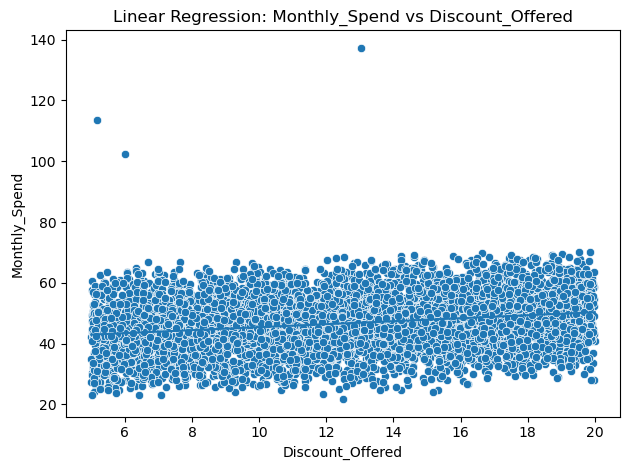

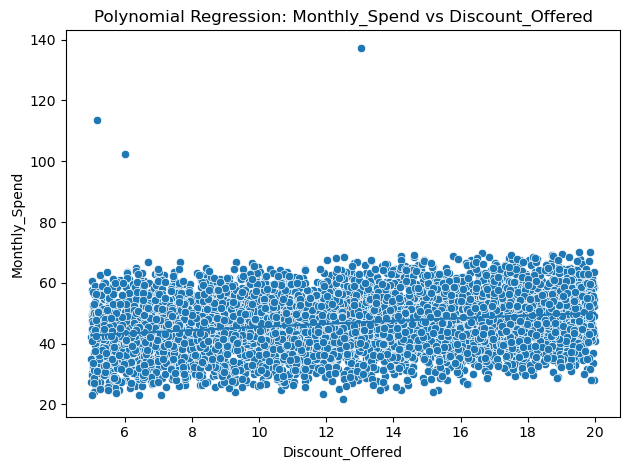

In [47]:
# Create the class' instance with required parameters
regression_exp = RegressionExperiment(df, target_col="Monthly_Spend")

# Combined features for multi-feature regressions
multi_features = ['Satisfaction_Score', 'Subscription_Length', 'Discount_Offered', 'Age', 'Support_Tickets_Raised', 'Last_Activity', 'Churned']

# A loop to perform both single and multi-feature regressions
for feature in ['Satisfaction_Score', 'Subscription_Length', 'Discount_Offered', multi_features]:
    regression_exp.prepare_feature(feature)
    regression_exp.linear_regression(feature)
    regression_exp.polynomial_regression(feature, poly_degree=2)

In [48]:
# Convert the results dictionary to pandas dataframe and display
results_df = pd.DataFrame(regression_exp.results)
results_df

,Linear_Satisfaction_Score,Poly2_Satisfaction_Score,Linear_Subscription_Length,Poly2_Subscription_Length,Linear_Discount_Offered,Poly2_Discount_Offered,"Linear_['Satisfaction_Score', 'Subscription_Length', 'Discount_Offered', 'Age', 'Support_Tickets_Raised', 'Last_Activity', 'Churned']","Poly2_['Satisfaction_Score', 'Subscription_Length', 'Discount_Offered', 'Age', 'Support_Tickets_Raised', 'Last_Activity', 'Churned']"
Mean Absolute Error,5.411135,5.411029,6.407914,6.407495,7.372999,7.374238,1.758714,1.778698
Mean Squared Error,46.782277,46.777045,60.925378,60.925443,84.892454,84.961736,13.477413,12.651926
Root Mean Squared Error,6.839757,6.839375,7.805471,7.805475,9.213710,9.217469,3.671160,3.556955
Coefficient of Determination (R2),0.466833,0.466893,0.305647,0.305647,0.032500,0.031710,0.846401,0.855809


#### Interpretation of the results
1. Based on the single linear models results, the best single predictor for "Monthly_Spend" is "Satisfaction_Score" with the best R2 score of 0.467 and lowest errors compared to others.

2. Comparing single polynomial models and single linear models performances, we notice virtually no difference. Either the improvement or the decrease is so negligeable that it is very difficult to notice it.

3. The multi-feature linear regression performs much better than all the other models with a better R2 score and lower errors.

4. The multi poly degree 2 regression model performs slighly better than the multi linear model. Although the difference is small.

#### Random Forest
The `random_forest()` method is called as part of the `RegressionExperiment` with all available features. This means other numerical features (Age, Support_Tickets_Raised, Last_Activity) are added to the ones prviously used as well as categorical features (Gender, Region, Payment_Method)

Using pipeline instead of doing everything manually (as we did earlier) prevents mistakes and data leakage.

In [49]:
# Define all numerical and categorical features
num_features = ['Age', 'Subscription_Length', 'Support_Tickets_Raised', 'Satisfaction_Score', 'Discount_Offered', 'Last_Activity', 'Churned']
cat_features = ['Gender', 'Region', 'Payment_Method']

In [73]:
# Call random_forest method with 300 trees
regression_exp.random_forest(num_features, cat_features, n_trees=300)

{'Mean Absolute Error': 1.8765373666666665,
 'Mean Squared Error': 12.64427263177442,
 'Root Mean Squared Error': np.float64(3.5558786019455755),
 'Coefficient of Determination (R2)': 0.8505306884181152}

In [74]:
# Call random_forest method with 200 trees
regression_exp.random_forest(num_features, cat_features, n_trees=200)

{'Mean Absolute Error': 1.8889442000000007,
 'Mean Squared Error': 13.03448823863498,
 'Root Mean Squared Error': np.float64(3.6103307658211845),
 'Coefficient of Determination (R2)': 0.8459179076101953}

In [51]:
pd.DataFrame(regression_exp.results)

,Linear_Satisfaction_Score,Poly2_Satisfaction_Score,Linear_Subscription_Length,Poly2_Subscription_Length,Linear_Discount_Offered,Poly2_Discount_Offered,"Linear_['Satisfaction_Score', 'Subscription_Length', 'Discount_Offered', 'Age', 'Support_Tickets_Raised', 'Last_Activity', 'Churned']","Poly2_['Satisfaction_Score', 'Subscription_Length', 'Discount_Offered', 'Age', 'Support_Tickets_Raised', 'Last_Activity', 'Churned']",Random_Forest(all features)
Mean Absolute Error,5.411135,5.411029,6.407914,6.407495,7.372999,7.374238,1.758714,1.778698,1.888944
Mean Squared Error,46.782277,46.777045,60.925378,60.925443,84.892454,84.961736,13.477413,12.651926,13.034488
Root Mean Squared Error,6.839757,6.839375,7.805471,7.805475,9.213710,9.217469,3.671160,3.556955,3.610331
Coefficient of Determination (R2),0.466833,0.466893,0.305647,0.305647,0.032500,0.031710,0.846401,0.855809,0.845918


Random Forest performs slightly worse than multi-feature polynomial regression. Increasing the number of trees from 200 to 300, doesn't help the model to outperform the multi-feature polynomial model.

#### Artificial Neural Network
The `neural_network()` method also is called as part of the `RegressionExperiment` with all available features. 
We will create different neural network models by tuning hyperparameters such dropout rate, number of hidden layers and learning rate.

How the tuning will be explored:

1. Architecture

2 hidden layers vs 3 hidden layers

units = 32, 64, 128

2. Regularisation

dropout rate 10% vs 20% dropout rate 

3. Optimisation

learning rate = 0.01 vs 0.001 vs 0.0001

In [53]:
# Default neural network model with dropout of 20%, 2 hidden layers and learning rate of 0.001
regression_exp.neural_network(num_features, cat_features)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_34 (Dense)                     │ (None, 64)                  │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_23 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_35 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_24 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_36 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 1329.9692 - mean_squared_error: 1329.9692 - val_loss: 109.3721 - val_mean_squared_error: 109.3721
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 108.3733 - mean_squared_error: 108.3733 - val_loss: 45.2425 - val_mean_squared_error: 45.2425
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 68.6424 - mean_squared_error: 68.6424 - val_loss: 23.6143 - val_mean_squared_error: 23.6143
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 55.5492 - mean_squared_error: 55.5492 - val_loss: 17.1526 - val_mean_squared_error: 17.1526
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 49.0603 - mean_squared_error: 49.0603 - val_loss: 13.6125 - val_mean_squared_error: 13.6125
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 46.7827 - mean_squared_error: 46.7827 - val_loss: 12.1753 - val_mean_squared_error: 12.1753
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 45.2652 - mea

{'Mean Absolute Error': 1.8545214279174804,
 'Mean Squared Error': 9.195165062180386,
 'Root Mean Squared Error': np.float64(3.0323530569807313),
 'Coefficient of Determination (R2)': 0.8913029612891993}

In [65]:
# Neural network model with dropout of 10%, 2 hidden layers and learning rate of 0.001
regression_exp.neural_network(num_features, cat_features, dropout_rate=0.1)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_68 (Dense)                     │ (None, 64)                  │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_46 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_69 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_47 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_70 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 1147.3062 - mean_squared_error: 1147.3062 - val_loss: 88.8553 - val_mean_squared_error: 88.8553
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 81.5235 - mean_squared_error: 81.5235 - val_loss: 40.7170 - val_mean_squared_error: 40.7170
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 50.2930 - mean_squared_error: 50.2930 - val_loss: 22.8158 - val_mean_squared_error: 22.8158
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 38.4031 - mean_squared_error: 38.4031 - val_loss: 15.4139 - val_mean_squared_error: 15.4139
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 34.4050 - mean_squared_error: 34.4050 - val_loss: 12.2176 - val_mean_squared_error: 12.2176
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 30.7728 - mean_squared_error: 30.7728 - val_loss: 10.6492 - val_mean_squared_error: 10.6492
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 29.1711 - mean_sq

{'Mean Absolute Error': 1.6786433346557619,
 'Mean Squared Error': 7.980918490574527,
 'Root Mean Squared Error': np.float64(2.825051944756862),
 'Coefficient of Determination (R2)': 0.9056567010759}

In [55]:
# Neural network model with dropout of 10%, 3 hidden layers and learning rate of 0.001
regression_exp.neural_network(num_features, cat_features, dropout_rate=0.1, n_layers=3)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_40 (Dense)                     │ (None, 64)                  │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_27 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_41 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_28 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_42 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_29 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_43 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,281 (36.25 KB)

 Trainable params: 9,281 (36.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 960.1409 - mean_squared_error: 960.1409 - val_loss: 70.4282 - val_mean_squared_error: 70.4282
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 69.3429 - mean_squared_error: 69.3429 - val_loss: 21.8148 - val_mean_squared_error: 21.8148
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 46.0135 - mean_squared_error: 46.0135 - val_loss: 16.0209 - val_mean_squared_error: 16.0209
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 39.8763 - mean_squared_error: 39.8763 - val_loss: 11.1753 - val_mean_squared_error: 11.1753
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 36.5771 - mean_squared_error: 36.5771 - val_loss: 11.5712 - val_mean_squared_error: 11.5712
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 36.8663 - mean_squared_error: 36.8663 - val_loss: 9.4133 - val_mean_squared_error: 9.4133
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 34.9610 - mean_square

{'Mean Absolute Error': 1.765489677658081,
 'Mean Squared Error': 8.640282344999898,
 'Root Mean Squared Error': np.float64(2.9394357188072506),
 'Coefficient of Determination (R2)': 0.897862289782104}

In [56]:
# Neural network model with dropout of 10%, 2 hidden layers and learning rate of 0.01
regression_exp.neural_network(num_features, cat_features, dropout_rate=0.1, learning_rate=0.01 )

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_44 (Dense)                     │ (None, 64)                  │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_30 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_45 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_31 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_46 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 230.0459 - mean_squared_error: 230.0459 - val_loss: 13.9711 - val_mean_squared_error: 13.9711
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 31.6371 - mean_squared_error: 31.6371 - val_loss: 9.5420 - val_mean_squared_error: 9.5420
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 29.5454 - mean_squared_error: 29.5454 - val_loss: 10.5789 - val_mean_squared_error: 10.5789
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 27.6347 - mean_squared_error: 27.6347 - val_loss: 9.1106 - val_mean_squared_error: 9.1106
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 27.8720 - mean_squared_error: 27.8720 - val_loss: 11.6508 - val_mean_squared_error: 11.6508
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 29.1630 - mean_squared_error: 29.1630 - val_loss: 11.0286 - val_mean_squared_error: 11.0286
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 27.5184 - mean_squared_

{'Mean Absolute Error': 1.7061590941619873,
 'Mean Squared Error': 8.352506571323403,
 'Root Mean Squared Error': np.float64(2.890070340203401),
 'Coefficient of Determination (R2)': 0.9012641182647705}

In [57]:
# Neural network model with dropout of 10%, 2 hidden layers and learning rate of 0.0001
regression_exp.neural_network(num_features, cat_features, dropout_rate=0.1, learning_rate=0.0001 )

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_47 (Dense)                     │ (None, 64)                  │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_32 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_48 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_33 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_49 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2263.1162 - mean_squared_error: 2263.1162 - val_loss: 2338.3572 - val_mean_squared_error: 2338.3572
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2200.4565 - mean_squared_error: 2200.4565 - val_loss: 2252.7559 - val_mean_squared_error: 2252.7559
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2080.3821 - mean_squared_error: 2080.3821 - val_loss: 2074.2295 - val_mean_squared_error: 2074.2295
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1836.3651 - mean_squared_error: 1836.3651 - val_loss: 1742.2751 - val_mean_squared_error: 1742.2751
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1446.9193 - mean_squared_error: 1446.9193 - val_loss: 1277.2300 - val_mean_squared_error: 1277.2300
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 974.1526 - mean_squared_error: 974.1526 - val_loss: 779.7826 - val_mean_squared_error: 779.7826
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━

{'Mean Absolute Error': 1.8165718218231202,
 'Mean Squared Error': 9.272313678265167,
 'Root Mean Squared Error': np.float64(3.045047401645033),
 'Coefficient of Determination (R2)': 0.8903909791711683}

In [58]:
# Neural network model with dropout of 10%, 2 hidden layers with 32 units, and learning rate of 0.001
regression_exp.neural_network(num_features, cat_features, hidden_units=32,dropout_rate=0.1)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_50 (Dense)                     │ (None, 32)                  │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_34 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_51 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_35 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_52 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1678.7438 - mean_squared_error: 1678.7438 - val_loss: 493.7352 - val_mean_squared_error: 493.7352
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 160.0440 - mean_squared_error: 160.0440 - val_loss: 77.9478 - val_mean_squared_error: 77.9478
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 83.1344 - mean_squared_error: 83.1344 - val_loss: 43.5706 - val_mean_squared_error: 43.5706
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 61.0034 - mean_squared_error: 61.0034 - val_loss: 29.2840 - val_mean_squared_error: 29.2840
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 50.9143 - mean_squared_error: 50.9143 - val_loss: 21.8233 - val_mean_squared_error: 21.8233
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 46.1795 - mean_squared_error: 46.1795 - val_loss: 16.9101 - val_mean_squared_error: 16.9101
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 45.0080 - mea

{'Mean Absolute Error': 1.8701153937530517,
 'Mean Squared Error': 9.257617914381486,
 'Root Mean Squared Error': np.float64(3.042633384813472),
 'Coefficient of Determination (R2)': 0.8905646993822736}

In [59]:
# Neural network model with dropout of 10%, 2 hidden layers with 128 units, and learning rate of 0.001
regression_exp.neural_network(num_features, cat_features, hidden_units=128,dropout_rate=0.1)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_53 (Dense)                     │ (None, 128)                 │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_36 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_54 (Dense)                     │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_37 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_55 (Dense)                     │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,433 (72.00 KB)

 Trainable params: 18,433 (72.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 789.8604 - mean_squared_error: 789.8604 - val_loss: 79.2501 - val_mean_squared_error: 79.2501
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 57.4310 - mean_squared_error: 57.4310 - val_loss: 25.6937 - val_mean_squared_error: 25.6937
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 31.9605 - mean_squared_error: 31.9605 - val_loss: 14.5741 - val_mean_squared_error: 14.5741
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 25.1659 - mean_squared_error: 25.1659 - val_loss: 11.5119 - val_mean_squared_error: 11.5119
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 22.4906 - mean_squared_error: 22.4906 - val_loss: 10.0027 - val_mean_squared_error: 10.0027
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 21.5952 - mean_squared_error: 21.5952 - val_loss: 9.8657 - val_mean_squared_error: 9.8657
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 22.2655 - mean_square

{'Mean Absolute Error': 1.8575100272369385,
 'Mean Squared Error': 8.985072963630973,
 'Root Mean Squared Error': np.float64(2.997511128191349),
 'Coefficient of Determination (R2)': 0.8937864826631423}

In [60]:
# Neural network model with dropout of 20%, 2 hidden layers with 32 units, and learning rate of 0.001
regression_exp.neural_network(num_features, cat_features, hidden_units=32)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_56 (Dense)                     │ (None, 32)                  │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_38 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_57 (Dense)                     │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_39 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_58 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1779.7979 - mean_squared_error: 1779.7979 - val_loss: 763.6476 - val_mean_squared_error: 763.6476
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 263.1810 - mean_squared_error: 263.1810 - val_loss: 119.8486 - val_mean_squared_error: 119.8486
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 151.9487 - mean_squared_error: 151.9487 - val_loss: 73.7907 - val_mean_squared_error: 73.7907
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 119.3195 - mean_squared_error: 119.3195 - val_loss: 47.6133 - val_mean_squared_error: 47.6133
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 95.4723 - mean_squared_error: 95.4723 - val_loss: 33.1063 - val_mean_squared_error: 33.1063
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 88.5646 - mean_squared_error: 88.5646 - val_loss: 30.5863 - val_mean_squared_error: 30.5863
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 79.3975

{'Mean Absolute Error': 1.8097699353027343,
 'Mean Squared Error': 9.103421613286105,
 'Root Mean Squared Error': np.float64(3.0171876993793583),
 'Coefficient of Determination (R2)': 0.8923874705012134}

In [61]:
# Neural network model with dropout of 20%, 2 hidden layers with 128 units, and learning rate of 0.001
regression_exp.neural_network(num_features, cat_features, hidden_units=128)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_59 (Dense)                     │ (None, 128)                 │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_40 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_60 (Dense)                     │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_41 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_61 (Dense)                     │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,433 (72.00 KB)

 Trainable params: 18,433 (72.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 948.3204 - mean_squared_error: 948.3204 - val_loss: 93.3184 - val_mean_squared_error: 93.3184
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 79.7924 - mean_squared_error: 79.7924 - val_loss: 35.1860 - val_mean_squared_error: 35.1860
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 49.7298 - mean_squared_error: 49.7298 - val_loss: 17.3153 - val_mean_squared_error: 17.3153
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 37.5276 - mean_squared_error: 37.5276 - val_loss: 12.8395 - val_mean_squared_error: 12.8395
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 35.5173 - mean_squared_error: 35.5173 - val_loss: 10.6064 - val_mean_squared_error: 10.6064
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 34.1212 - mean_squared_error: 34.1212 - val_loss: 10.5817 - val_mean_squared_error: 10.5817
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 31.6719 - mean_squa

{'Mean Absolute Error': 1.7262239779663087,
 'Mean Squared Error': 8.424558036168285,
 'Root Mean Squared Error': np.float64(2.902508920945513),
 'Coefficient of Determination (R2)': 0.9004123901217242}

In [62]:
# Neural network model with dropout of 20%, 2 hidden layers and learning rate of 0.0001
regression_exp.neural_network(num_features, cat_features, learning_rate=0.0001)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_62 (Dense)                     │ (None, 64)                  │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_42 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_63 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_43 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_64 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 2208.6384 - mean_squared_error: 2208.6384 - val_loss: 2271.6440 - val_mean_squared_error: 2271.6440
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2109.0857 - mean_squared_error: 2109.0857 - val_loss: 2126.8523 - val_mean_squared_error: 2126.8523
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1912.5737 - mean_squared_error: 1912.5737 - val_loss: 1856.3495 - val_mean_squared_error: 1856.3495
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1583.0891 - mean_squared_error: 1583.0891 - val_loss: 1439.4928 - val_mean_squared_error: 1439.4928
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1127.0178 - mean_squared_error: 1127.0178 - val_loss: 929.1788 - val_mean_squared_error: 929.1788
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 656.5007 - mean_squared_error: 656.5007 - val_loss: 486.5248 - val_mean_squared_error: 486.5248
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━

{'Mean Absolute Error': 1.856988637237549,
 'Mean Squared Error': 9.34875036719699,
 'Root Mean Squared Error': np.float64(3.057572626643068),
 'Coefficient of Determination (R2)': 0.8894874128208566}

In [63]:
# Neural network model with dropout of 10%, 2 hidden layers with 128 units, and learning rate of 0.0001
regression_exp.neural_network(num_features, cat_features, hidden_units=128,dropout_rate=0.1, learning_rate=0.0001)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_65 (Dense)                     │ (None, 128)                 │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_44 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_66 (Dense)                     │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_45 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_67 (Dense)                     │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,433 (72.00 KB)

 Trainable params: 18,433 (72.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 2216.0999 - mean_squared_error: 2216.0999 - val_loss: 2222.2141 - val_mean_squared_error: 2222.2141
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1969.6438 - mean_squared_error: 1969.6438 - val_loss: 1853.5256 - val_mean_squared_error: 1853.5256
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1471.6969 - mean_squared_error: 1471.6969 - val_loss: 1189.8387 - val_mean_squared_error: 1189.8387
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 766.0041 - mean_squared_error: 766.0041 - val_loss: 474.1584 - val_mean_squared_error: 474.1584
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 276.9543 - mean_squared_error: 276.9543 - val_loss: 186.1311 - val_mean_squared_error: 186.1311
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 161.7671 - mean_squared_error: 161.7671 - val_loss: 139.2659 - val_mean_squared_error: 139.2659
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4m

{'Mean Absolute Error': 1.8370033607482912,
 'Mean Squared Error': 9.276045785950206,
 'Root Mean Squared Error': np.float64(3.0456601560171164),
 'Coefficient of Determination (R2)': 0.8903468615233859}

In [64]:
pd.DataFrame(regression_exp.results)

,Linear_Satisfaction_Score,Poly2_Satisfaction_Score,Linear_Subscription_Length,Poly2_Subscription_Length,Linear_Discount_Offered,Poly2_Discount_Offered,"Linear_['Satisfaction_Score', 'Subscription_Length', 'Discount_Offered', 'Age', 'Support_Tickets_Raised', 'Last_Activity', 'Churned']","Poly2_['Satisfaction_Score', 'Subscription_Length', 'Discount_Offered', 'Age', 'Support_Tickets_Raised', 'Last_Activity', 'Churned']",Random_Forest(all features),ANN_drop0.2_learning0.001_layer2_units64,ANN_drop0.1_learning0.001_layer2_units64,ANN_drop0.1_learning0.001_layer3_units64,ANN_drop0.1_learning0.01_layer2_units64,ANN_drop0.1_learning0.0001_layer2_units64,ANN_drop0.1_learning0.001_layer2_units32,ANN_drop0.1_learning0.001_layer2_units128,ANN_drop0.2_learning0.001_layer2_units32,ANN_drop0.2_learning0.001_layer2_units128,ANN_drop0.2_learning0.0001_layer2_units64,ANN_drop0.1_learning0.0001_layer2_units128
Mean Absolute Error,5.411135,5.411029,6.407914,6.407495,7.372999,7.374238,1.758714,1.778698,1.888944,1.854521,1.645329,1.765490,1.706159,1.816572,1.870115,1.857510,1.809770,1.726224,1.856989,1.837003
Mean Squared Error,46.782277,46.777045,60.925378,60.925443,84.892454,84.961736,13.477413,12.651926,13.034488,9.195165,7.973568,8.640282,8.352507,9.272314,9.257618,8.985073,9.103422,8.424558,9.348750,9.276046
Root Mean Squared Error,6.839757,6.839375,7.805471,7.805475,9.213710,9.217469,3.671160,3.556955,3.610331,3.032353,2.823751,2.939436,2.890070,3.045047,3.042633,2.997511,3.017188,2.902509,3.057573,3.045660
Coefficient of Determination (R2),0.466833,0.466893,0.305647,0.305647,0.032500,0.031710,0.846401,0.855809,0.845918,0.891303,0.905744,0.897862,0.901264,0.890391,0.890565,0.893786,0.892387,0.900412,0.889487,0.890347


According to the results of the 11 created models, here is some key insight:
1. Increasing depth(2 to 3 layers) makes the performance drop slighly. This is because more layers means more parameters and our dataset is not large enough to justify a deeper network. More layers also make the optimisation harder.
2. Increasing width(32 to 64 to 128 units). Models with 32 and 128 have similar and sometimes slightly worse performance than models with 64.
3. Dropout of 0.1 has slightly better performance in some cases while 0.2 has slightly better performance in others. This means both values worked well because the model is well regularised (early stopping is effective) and the small differences are due to randomness.
4. The learning rates 0.001 has slightly better performances than other rates.

**So the best overall model is the one with 2 hidden layers, 64 units, dropout of 0.1 and learning rate of 0.001. It is important to note that all neural network models outperformed the random forest model.**

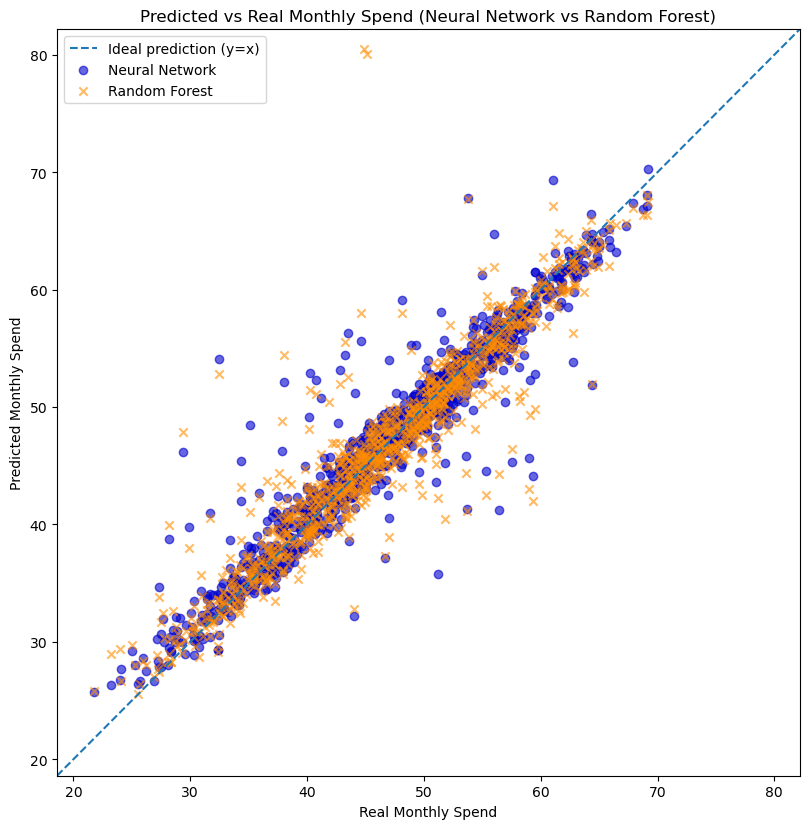

In [68]:
# Neural network and Random Forest Comparison plot
regression_exp.plot_predicted()

### Classification Models

`ClassificationExperiment` class
This class is a complete worklow to compare multiple classification models to predict whether a customer churned or not and evaluate their performance.

---
### Initialisation

**Purpose:**  
Initialise the classification experiment framework and store shared data structures.

**Parameters:**
- `df` *(pd.DataFrame)*: Input dataset containing features and target variable  
- `target_col` *(str)*: Name of the binary target variable  

**Sets:**
- `self.df`: Reference to the dataset  
- `self.target`: Target column name  
- `self.results`: Dictionary to store performance metrics for each classifier  

---

### Logistic Regression Classifier
**Purpose:**  
Train and evaluate a baseline linear classification model using both numerical and categorical features.

**Process:**
- Separates numerical and categorical features  
- Encodes categorical variables using one-hot encoding  
- Concatenates numerical and encoded categorical features  
- Splits data into training (80%) and test (20%) sets with stratification  
- Applies feature standardisation  
- Trains a logistic regression classifier  

**Evaluation:**
- Generates class predictions and class probabilities  
- Computes Accuracy, Precision, Recall, F1-score, and ROC-AUC  

**Output:**
- Stores evaluation metrics under `"Logistic_Regression"`  

---
### Random Forest Classifier

**Purpose:**  
Model non-linear relationships and feature interactions using an ensemble-based classifier.

**Process:**
- Combines numerical and categorical features  
- Applies one-hot encoding to categorical variables using a `ColumnTransformer`  
- Builds a preprocessing and modelling pipeline  
- Uses class weighting to address class imbalance  
- Splits data into training and test sets with stratification  
- Trains a random forest classifier  

**Evaluation:**
- Generates predictions and class probabilities  
- Computes Accuracy, Precision, Recall, F1-score, and ROC-AUC  

**Output:**
- Stores evaluation metrics under `"Random_Forest_Classifier"`  
- Saves predictions and probabilities for later visualisation  

---
### Neural Network Classifier
**Purpose:**  
Train a feedforward artificial neural network for binary classification.

**Parameters:**
- `epochs`: Number of training epochs  
- `dropout_rate`: Dropout rate for regularisation  
- `n_layers`: Number of hidden layers  
- `hidden_units`: Number of units per hidden layer  
- `learning_rate`: Optimiser learning rate  

**Process:**
- Encodes categorical variables using one-hot encoding  
- Concatenates numerical and categorical features  
- Scales features using min–max normalisation  
- Builds a neural network with configurable depth and dropout  
- Applies early stopping to reduce overfitting  

**Evaluation:**
- Predicts class probabilities and binary labels  
- Computes Accuracy, Precision, Recall, F1-score, and ROC-AUC  

**Output:**
- Stores metrics using a configuration-specific key  
- Saves predictions, probabilities, and training history for analysis  

---
### Evaluation Metrics
**Purpose:**  
Provide a consistent evaluation of all classification models.

**Metrics:**
- Accuracy  
- Precision  
- Recall  
- F1-score  
- ROC-AUC  

**Output:**
- Returns a dictionary of evaluation metrics for each model  

---
### Model Comparison Visualisation

**Purpose:**  
Visually compare the performance of Random Forest and Neural Network classifiers.

**Process:**
- Computes ROC curves and AUC scores  
- Generates confusion matrices for both models  
- Plots confusion matrices and ROC curves side-by-side  

**Output:**
- Saved confusion matrix figure  
- Saved ROC curve plot

In [44]:
class ClassificationExperiment:
    def __init__(self, df, target_col):
        self.df = df
        self.target = target_col
        self.results = {}
        
    # -----------------------------------------------------------
    # Linear classification method
    def logistic(self, num_features, cat_features):
        
        # Define input numerical and categorical features separately
        x_num = self.df[num_features] 
        x_cat = self.df[cat_features]
        y = self.df[self.target]

        # Encode categorical variables
        # sparse_output=False is needed because Keras can't handle sparse matrix
        encoder = OneHotEncoder(sparse_output=False)
        x_cat_encoded = encoder.fit_transform(x_cat)

        # Concatenate numerical and categorical features
        x = np.hstack([x_num.values, x_cat_encoded])
        
        # Split dataset into training and checking tests
        # Test set will be 20% of the dataset
        x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1, stratify=y)
        
        # Apply standarisation by scaling the input feature
        scale = StandardScaler()
        scale.fit(x_train)
        x_train_scaled = scale.transform(x_train)
        x_test_scaled = scale.transform(x_test)
        
        # Create the model and train it over the scaled training set
        model = LogisticRegression()
        model.fit(x_train_scaled, y_train)
        
        # Perform prediction on the test set and compute evaluation metrics
        y_pred = model.predict(x_test_scaled)
        y_prob = model.predict_proba(x_test_scaled)[:, 1] # Compute probability of churn of each customer. It's needed for ROC-AUC metrics
        metrics = self.evaluate(y_test ,y_pred, y_prob)

        # Store the performance results
        self.results["Logistic_Regression"] = metrics

        return metrics
        
    # -----------------------------------------------------------
    # Define random forest classifier method
    def rf_classifier(self, num_features, cat_features, n_trees=200):
        # Define input features as concatenation of both numerical and categorical features
        x = self.df[num_features + cat_features]
        y = self.df[self.target]
    
        # Preprocessing: Transform only categorical columns using One Hot Enoder
        # ColumnTransformer applies One Hot Encoder on cat_featurs, lets num_features untouched and concatenates the output for us
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', 'passthrough', num_features),
                ('cat', OneHotEncoder(drop='first',  handle_unknown='ignore'), cat_features)])
    
        # Define Random forest classifier 
        # random_state is set for reproductivity
        # With class_weight = 'balanced' will pay more attention to the minority class
        random_classifier = RandomForestClassifier(n_estimators=n_trees, random_state=1, class_weight='balanced')
    
        # Now let's define the full pipeline
        model = Pipeline(steps=[('preprocessing', preprocessor), ('regressor', random_classifier)])
    
        # Split training and testing set
        # Stratify=y will ensure we have the same ratio of churn and non-churn in both sets
        x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y)
    
        # Train the model
        model.fit(x_train, y_train)
    
        # Make predictions and compute evaluation
        y_pred = model.predict(x_test)
        y_prob = model.predict_proba(x_test)[:, 1] # Compute probability of churn of each customer. It's needed for ROC-AUC metrics
        metrics = self.evaluate(y_test, y_pred, y_prob)
    
        # Store the performance results
        self.results["Random_Forest_Classifier"] = metrics
        
        # Save the prediction and test set for eventual plotting
        self.rf_y_test = y_test
        self.rf_y_pred = y_pred
        self.rf_y_prob = y_prob
    
        return metrics

    # -----------------------------------------------------------
    # Define artificial neural network classifier method
    def nn_classifier(self, num_features, cat_features, epochs=200, dropout_rate=0.2,
                      n_layers=2, hidden_units=64, learning_rate=0.001):
        # Define input numerical and categorical features separately
        x_num = self.df[num_features] 
        x_cat = self.df[cat_features]
        y = self.df[self.target]

        # Encode categorical variables
        # sparse_output=False is needed because Keras can't handle sparse matrix
        encoder = OneHotEncoder(sparse_output=False)
        x_cat_encoded = encoder.fit_transform(x_cat)

        # Concatenate numerical and categorical features
        x = np.hstack([x_num.values, x_cat_encoded])
        
        # Prepare the data and proceed to scaling
        x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y)
        
        scale = MinMaxScaler()
        scale.fit(x_train)
        x_train_scaled = scale.transform(x_train)
        x_test_scaled = scale.transform(x_test)

        # Build the neural network model
        model = Sequential()
        model.add(Dense(units = hidden_units, input_dim = x_train_scaled.shape[1], activation = 'relu'))
        model.add(Dropout(dropout_rate))
        
        for layer in range(n_layers-1):
            model.add(Dense(units = hidden_units, activation = 'relu'))
            model.add(Dropout(dropout_rate))
        
        model.add(Dense(units = 1, activation = 'sigmoid'))
        model.summary()
        
        adam_optimizer = Adam(learning_rate)
        
        model.compile(optimizer=adam_optimizer, loss='binary_crossentropy', metrics=['accuracy'])
        early_stopping = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

        # Train the model
        history = model.fit(x = x_train_scaled, y = y_train, batch_size = None, epochs = epochs,
                   verbose = 'auto', validation_split = 0.1, callbacks = [early_stopping])

        # Perform prediction and evaluate performance
        y_prob = model.predict(x_test_scaled) # Return the probability of each customer being churn
        y_pred = (y_prob >= 0.5).astype(int) # Gives the actual class based on the probability. over 0.5 (inclusive) is churn
        
        metrics = self.evaluate(y_test, y_pred, y_prob)
        

        # Store results
        self.results[f"ANN_drop{dropout_rate}_learning{learning_rate}_layer{n_layers}_units{hidden_units}"] = metrics

        # Convert history to dataframe and save it for plot
        # Save the prediction and test set for eventual plotting
        self.nnc_y_test = y_test
        self.nnc_y_pred = y_pred
        self.nnc_y_prob = y_prob
        self.history_class_df = pd.DataFrame(history.history)

        return metrics

    # -----------------------------------------------------------
    # Define how to evaluate the metrics
    def evaluate(self, y_true, y_pred, y_prob):
        return {
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'F1-score': f1_score(y_true, y_pred),
            'ROC-AUC': roc_auc_score(y_true, y_prob)
        }
        
    # -----------------------------------------------------------
    # Define plotting method to compare Random Forest and Neural Network classifications
    def plot_classification_comparison(self):
    
        # ROC curves
        rf_fpr, rf_tpr, _ = roc_curve(self.rf_y_test, self.rf_y_prob)
        nn_fpr, nn_tpr, _ = roc_curve(self.nnc_y_test, self.nnc_y_prob)
    
        rf_auc = roc_auc_score(self.rf_y_test, self.rf_y_prob)
        nn_auc = roc_auc_score(self.nnc_y_test, self.nnc_y_prob)
    
        # Confusion matrices
        rf_cm = confusion_matrix(self.rf_y_test, self.rf_y_pred)
        nn_cm = confusion_matrix(self.nnc_y_test, self.nnc_y_pred)
    
        # Create figure
        fig, axes = plt.subplots(1, 2, figsize=(12,5))
    
        # Random Forest confusion matrix
        sns.heatmap(
            rf_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not churned', 'Churned'],
            yticklabels=['Not churned', 'Churned'],
            ax=axes[0]
        )
        axes[0].set_title("Random Forest Confusion Matrix")
        axes[0].set_xlabel("Predicted label")
        axes[0].set_ylabel("True label")
    
        # Neural Network confusion matrix
        sns.heatmap(
            nn_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Not churned', 'Churned'],
            yticklabels=['Not churned', 'Churned'],
            ax=axes[1]
        )
        axes[1].set_title("ANN Confusion Matrix")
        axes[1].set_xlabel("Predicted label")
        axes[1].set_ylabel("True label")
    
        plt.tight_layout()
        plt.savefig('./Matrices_rf_nn.png')
        plt.show()

        # ROC plot
        plt.figure(figsize=(7, 6))
        plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
        plt.plot(nn_fpr, nn_tpr, label=f"ANN (AUC = {nn_auc:.3f})")
        plt.plot([0, 1], [0, 1], linestyle='--', label="Random guess")
    
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("ROC Curve Comparison")
        plt.legend()
        plt.tight_layout()
        plt.savefig('./ROC_plot.png')

In [1]:
# Define all numerical and categorical features
num_features = ['Age', 'Subscription_Length', 'Support_Tickets_Raised', 'Satisfaction_Score', 'Discount_Offered', 'Last_Activity', 'Monthly_Spend']
cat_features = ['Gender', 'Region', 'Payment_Method']

In [28]:
# Create a classification experiment instance with the appropriate parameters
classificatin_exp = ClassificationExperiment(df, target_col='Churned')

# Perform logistic regression
classificatin_exp.logistic(num_features, cat_features)

{'Accuracy': 0.816,
 'Precision': 0.7959641255605381,
 'Recall': 0.7924107142857143,
 'F1-score': 0.7941834451901566,
 'ROC-AUC': np.float64(0.9053118530020704)}

In [29]:
# Perform random forest classification with 200 trees
classificatin_exp.rf_classifier(num_features, cat_features)

{'Accuracy': 0.977,
 'Precision': 0.9796839729119639,
 'Recall': 0.96875,
 'F1-score': 0.9741863075196409,
 'ROC-AUC': np.float64(0.9976222826086957)}

In [37]:
# Default neural network model with dropout of 20%, 2 hidden layers and learning rate of 0.001
classificatin_exp.nn_classifier(num_features, cat_features)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_26 (Dense)                     │ (None, 64)                  │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_27 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_28 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,313 (20.75 KB)

 Trainable params: 5,313 (20.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.6734 - loss: 0.6123 - val_accuracy: 0.7900 - val_loss: 0.4939
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7615 - loss: 0.4983 - val_accuracy: 0.8075 - val_loss: 0.4334
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7699 - loss: 0.4715 - val_accuracy: 0.8025 - val_loss: 0.4238
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7954 - loss: 0.4498 - val_accuracy: 0.8025 - val_loss: 0.4104
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7835 - loss: 0.4424 - val_accuracy: 0.8025 - val_loss: 0.4062
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7993 - loss: 0.4309 - val_accuracy: 0.8100 - val_loss: 0.3966
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8138 - loss: 0.4027 - val_accuracy: 0.8325 - val_loss: 0.3709
Epoch 8/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8271 - loss: 0.3824 - val_accu

{'Accuracy': 0.969,
 'Precision': 0.9445628997867804,
 'Recall': 0.9888392857142857,
 'F1-score': 0.9661941112322792,
 'ROC-AUC': np.float64(0.99805091873706)}

In [31]:
# Neural network model with dropout of 20%, 2 hidden layers and learning rate of 0.0001
classificatin_exp.nn_classifier(num_features, cat_features, learning_rate=0.0001)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                     │ (None, 64)                  │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_12 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,313 (20.75 KB)

 Trainable params: 5,313 (20.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5631 - loss: 0.6826 - val_accuracy: 0.6250 - val_loss: 0.6655
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6148 - loss: 0.6630 - val_accuracy: 0.6500 - val_loss: 0.6496
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6312 - loss: 0.6486 - val_accuracy: 0.6875 - val_loss: 0.6314
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6770 - loss: 0.6301 - val_accuracy: 0.7325 - val_loss: 0.6094
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6848 - loss: 0.6150 - val_accuracy: 0.7700 - val_loss: 0.5866
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7126 - loss: 0.5947 - val_accuracy: 0.7950 - val_loss: 0.5623
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7349 - loss: 0.5706 - val_accuracy: 0.7925 - val_loss: 0.5401
Epoch 8/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7421 - loss: 0.5516 - val_accu

{'Accuracy': 0.924,
 'Precision': 0.9025974025974026,
 'Recall': 0.9308035714285714,
 'F1-score': 0.9164835164835164,
 'ROC-AUC': np.float64(0.9689117494824017)}

In [40]:
# Neural network model with dropout of 20%, 3 hidden layers and learning rate of 0.001
classificatin_exp.nn_classifier(num_features, cat_features, n_layers=3)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_29 (Dense)                     │ (None, 64)                  │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_30 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_21 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_31 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_22 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_32 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,473 (37.00 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6354 - loss: 0.6348 - val_accuracy: 0.7775 - val_loss: 0.5051
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7499 - loss: 0.5057 - val_accuracy: 0.7925 - val_loss: 0.4370
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7715 - loss: 0.4763 - val_accuracy: 0.8075 - val_loss: 0.4252
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7863 - loss: 0.4588 - val_accuracy: 0.8025 - val_loss: 0.4113
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7929 - loss: 0.4421 - val_accuracy: 0.8275 - val_loss: 0.4018
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7974 - loss: 0.4299 - val_accuracy: 0.8225 - val_loss: 0.3806
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8135 - loss: 0.4036 - val_accuracy: 0.8375 - val_loss: 0.3630
Epoch 8/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8357 - loss: 0.3731 - val_accu

{'Accuracy': 0.968,
 'Precision': 0.940677966101695,
 'Recall': 0.9910714285714286,
 'F1-score': 0.9652173913043478,
 'ROC-AUC': np.float64(0.992971984989648)}

In [41]:
# Neural network model with dropout of 10%, 2 hidden layers and learning rate of 0.001
classificatin_exp.nn_classifier(num_features, cat_features, dropout_rate=0.1)

C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_33 (Dense)                     │ (None, 64)                  │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_23 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_34 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_24 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_35 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,313 (20.75 KB)

 Trainable params: 5,313 (20.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6812 - loss: 0.6096 - val_accuracy: 0.7850 - val_loss: 0.4856
Epoch 2/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7757 - loss: 0.4767 - val_accuracy: 0.7925 - val_loss: 0.4262
Epoch 3/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7815 - loss: 0.4477 - val_accuracy: 0.8100 - val_loss: 0.4082
Epoch 4/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8018 - loss: 0.4252 - val_accuracy: 0.8075 - val_loss: 0.4041
Epoch 5/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8107 - loss: 0.4055 - val_accuracy: 0.8250 - val_loss: 0.3767
Epoch 6/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8274 - loss: 0.3882 - val_accuracy: 0.8375 - val_loss: 0.3573
Epoch 7/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8435 - loss: 0.3629 - val_accuracy: 0.8525 - val_loss: 0.3363
Epoch 8/200
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8591 - loss: 0.3401 - val_accu

{'Accuracy': 0.982,
 'Precision': 0.9777777777777777,
 'Recall': 0.9821428571428571,
 'F1-score': 0.9799554565701559,
 'ROC-AUC': np.float64(0.9982207556935818)}

In [42]:
pd.DataFrame(classificatin_exp.results)

,Logistic_Regression,Random_Forest_Classifier,ANN_drop0.2_learning0.001_layer2_units64,ANN_drop0.2_learning0.0001_layer2_units64,ANN_drop0.2_learning0.001_layer3_units64,ANN_drop0.1_learning0.001_layer2_units64
Accuracy,0.816000,0.977000,0.969000,0.924000,0.968000,0.982000
Precision,0.795964,0.979684,0.944563,0.902597,0.940678,0.977778
Recall,0.792411,0.968750,0.988839,0.930804,0.991071,0.982143
F1-score,0.794183,0.974186,0.966194,0.916484,0.965217,0.979955
ROC-AUC,0.905312,0.997622,0.998051,0.968912,0.992972,0.998221


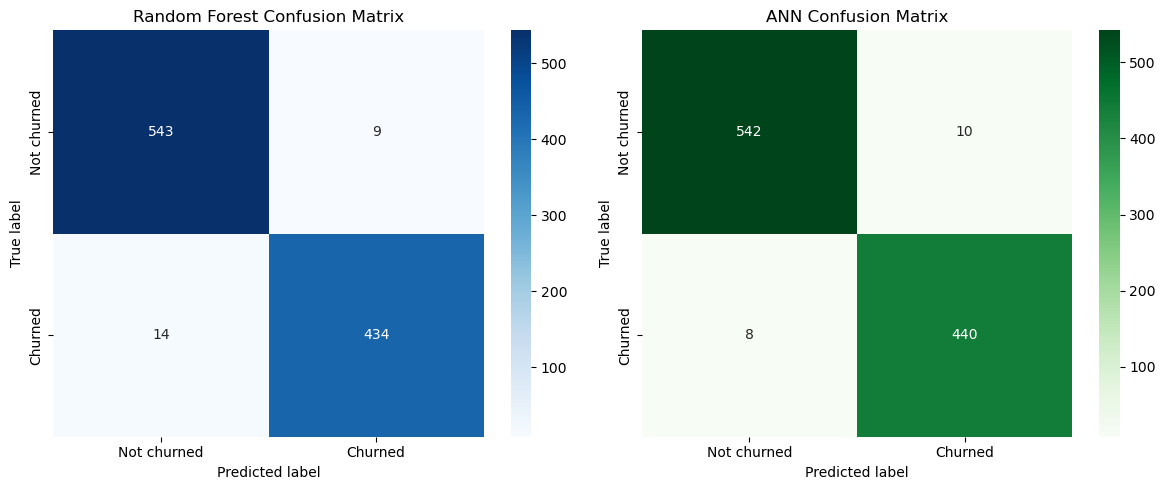

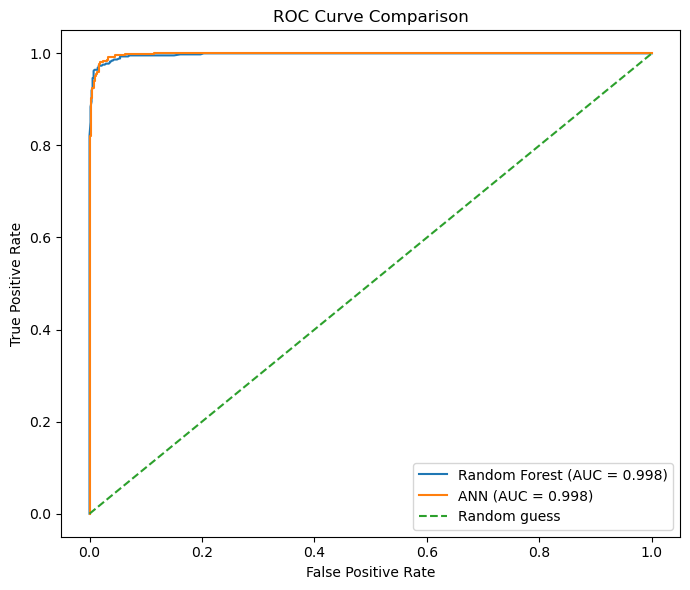

In [43]:
# Comparison plots
classificatin_exp.plot_classification_comparison()

From the ROC plot, we can see that both curves are close to the top-left corner and this means both models are stromg. 

From confusion matrix, ANN has fewer false negative (missed churners) and similar false positives (non-churners predicted churners) as Random Forest. ANN performs better.

**The best model for churners classification is ANN with 2 layers, 64 units, dropout of 0.1, learning rate of 0.001**


### Clustering Models
`ClusteringExperiment` class
This class is a complete worklow to compare multiple clustering models to identify customers behaviour and evaluate their performance.

---
### Initialisation

**Purpose:**  
Initialise the clustering experiment framework and store shared data structures.

**Parameters:**
- `df` *(pd.DataFrame)*: Input dataset containing features for clustering

**Sets:**
- `self.df`: Reference to the dataset  
- `self.results`: Dictionary to store clustering evaluation metrics  

---
### Feature Preparation

**Purpose:**  
Prepare and standardise features for clustering by handling numerical and categorical variables.

**Parameters:**
- `features` *(list)*: List of feature names to include in clustering

**Process:**
- Selects specified features from the dataset  
- Identifies categorical and numerical features  
- Encodes categorical features using one-hot encoding  
- Combines numerical and encoded categorical features  
- Applies standardisation using `StandardScaler`  

**Output:**
- `self.x_scaled`: Scaled feature matrix used for clustering  

---

### Elbow Method

**Purpose:**  
Identify an appropriate number of clusters for k-means clustering.

**Process:**
- Fits k-means models for different values of `k`  
- Records within-cluster inertia for each `k`  
- Plots inertia against the number of clusters  

**Output:**
- Elbow plot saved to disk  
- Visual guide for selecting the number of clusters  

---

### K-Means Clustering

**Purpose:**  
Partition the data into a specified number of clusters using k-means.

**Parameters:**
- `nb_clusters` *(int)*: Number of clusters to form

**Process:**
- Fits a k-means model on the scaled features  
- Predicts cluster assignments  
- Evaluates clustering quality using internal metrics  
- Visualises clusters using PCA projection  

**Output:**
- Davies–Bouldin score  
- Silhouette score  
- PCA scatter plot of clusters  

---

### Hierarchical Clustering

**Purpose:**  
Cluster the data using an agglomerative hierarchical approach.

**Parameters:**
- `nb_clusters` *(int)*: Number of clusters to form

**Process:**
- Applies agglomerative clustering with complete linkage  
- Predicts cluster assignments  
- Evaluates clustering quality using internal metrics  
- Visualises clusters using PCA projection  

**Output:**
- Davies–Bouldin score  
- Silhouette score  
- PCA scatter plot of clusters  

---

### Clustering Evaluation

**Purpose:**  
Quantitatively assess clustering quality using internal validation metrics.

**Metrics:**
- Davies–Bouldin Index  
- Silhouette Score  

**Output:**
- Dictionary containing clustering evaluation scores  

---

### PCA Visualisation

**Purpose:**  
Provide a two-dimensional visual representation of clustering results.

**Process:**
- Applies PCA to reduce features to two principal components  
- Projects clustered data onto PC1 and PC2  
- Displays explained variance for each component  
- Colours points by cluster assignment  

**Output:**
- Saved PCA scatter plot showing cluster separation  


In [68]:
class ClusteringExperiment:
    def __init__(self, df):
        self.df = df
        self.results = {}

    # -----------------------------------------------------------
    # Feature preparation method
    def prepare_feature(self, features):
        
        self.features = features
        
        x = self.df[features]

        # Identify categorical and numerical features
        cat_features = x.select_dtypes(include=['object', 'category']).columns.tolist()
        num_features = x.select_dtypes(exclude=['object', 'category']).columns.tolist()
    
        # Encode categorical features if any
        if cat_features:
            encoder = OneHotEncoder(drop='first', sparse_output=False)
            x_cat = encoder.fit_transform(x[cat_features])
        else:
            x_cat = None
    
        # Extract numerical features
        if num_features:
            x_num = x[num_features].values
        else:
            x_num = None
    
        # Combine numerical and categorical features
        if x_num is not None and x_cat is not None:
            x_combined = np.hstack([x_num, x_cat])
        elif x_num is not None:
            x_combined = x_num
        else:
            x_combined = x_cat
    
        # Scale combined features
        self.scale = StandardScaler()
        self.x_scaled = self.scale.fit_transform(x_combined)

        
    # -----------------------------------------------------------
    # Define elbow method
    def elbow_method(self):
        k_value = []
        inertia = []
        for k in range(10):
            kmeans = KMeans(n_clusters = k+1, random_state = 1)
            kmeans.fit(self.x_scaled)
            k_value.append(np.array(k+1))
            inertia.append(np.array(kmeans.inertia_))
    
        # Plot the elbow figure
        plt.plot(k_value, inertia)
        plt.xlabel("k values")
        plt.ylabel("inertia")
        plt.title(f"Elbow method: {self.features}")
    
        # Save plot
        plt.savefig(f"Elbow_method_{self.features}.png")
    
        plt.show()

    # -----------------------------------------------------------
    # Define k-means clustering method
    def k_means(self, nb_clusters):
        
        kmeans = KMeans(n_clusters = nb_clusters, random_state = 1)
        kmeans.fit(self.x_scaled)
        
        cluster_pred = kmeans.predict(self.x_scaled)

        metrics = self.evaluate(cluster_pred)

        self.results[f"kmeans: {self.features}"] = metrics

        # PCA visualisation
        self.plot_pca(cluster_pred, title='k-Means Clustering (PCA projection)', filename='kmeans_pca.png')

        return metrics

    # -----------------------------------------------------------
    # Define Hierarchical Clustering method
    def hierarchical_clustering(self, nb_clusters):
             
        agg_model = AgglomerativeClustering(n_clusters = nb_clusters, linkage = 'complete')
        agg_pred = agg_model.fit_predict(self.x_scaled)

        metrics = self.evaluate(agg_pred)

        self.results[f"hierarchical_{self.features}"] = metrics
        
        # PCA visualisation
        self.plot_pca(agg_pred, title='Hierarchical Clustering (PCA projection)', filename='hierarchical_pca.png')

        return metrics
    
    # -----------------------------------------------------------
    # Define evaluation method
    def evaluate(self, cluster_pred):

        return {
            "davies_bouldin_score": davies_bouldin_score(self.x_scaled, cluster_pred),
            "silhouette_score": silhouette_score(self.x_scaled, cluster_pred)
        }
        
    # -----------------------------------------------------------
    # Define PCA visualisation method
    def plot_pca(self, cluster_pred, title, filename):
        
        # 2D representation of the cluster
        pca = PCA(n_components=2)
        
        # fit pca on the same data used for clustering. This ensures there is no feature dominance due to scale.
        x_pca = pca.fit_transform(self.x_scaled)

        plt.figure() # Start fresh plot

        # The first principal component (PC1) will be on X-axis and the second one (PC2) on Y-axis
        sns.scatterplot(x=x_pca[:, 0], y=x_pca[:, 1], hue=cluster_pred, palette='tab10')

        plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
        plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
        plt.title(title)
        plt.legend(title='Clusters')

        # save
        plt.savefig(filename)
        plt.show()
        

In [69]:
grp_1 = ['Age', 'Gender', 'Region']
grp_2 = ['Last_Activity', 'Satisfaction_Score', 'Subscription_Length']
grp_3 = ['Last_Activity', 'Satisfaction_Score', 'Subscription_Length', 'Monthly_Spend']

#### Clustering with k-Means

In [70]:
# Create ClusteringExperiment's instance
clustering_exp = ClusteringExperiment(df)

# Preprocess the features for groupe 1
clustering_exp.prepare_feature(grp_1)

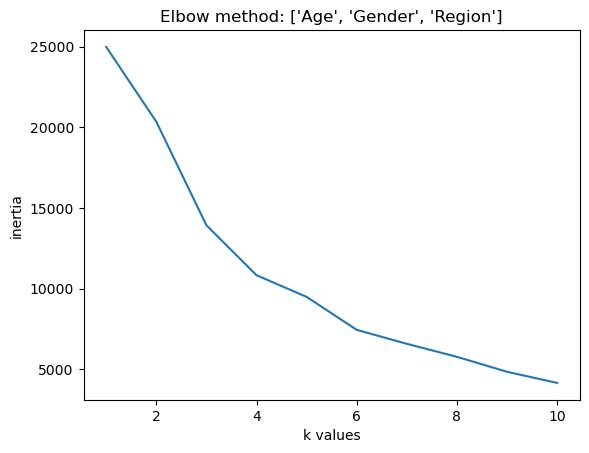

In [71]:
# Determine the appropriate number of clusters (k)
clustering_exp.elbow_method()

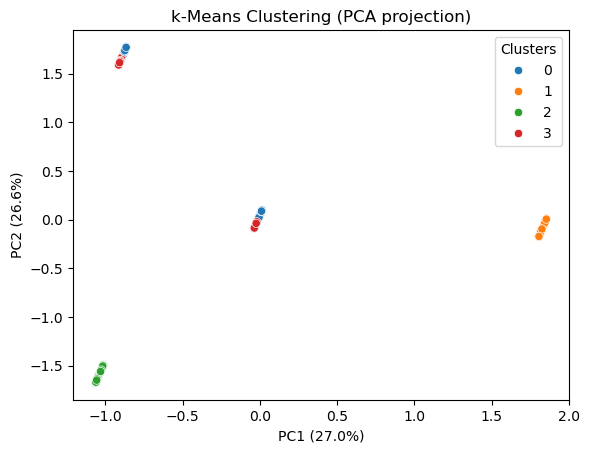

{'davies_bouldin_score': np.float64(1.2731588374137641),
 'silhouette_score': np.float64(0.3827881434482846)}

In [72]:
# Perform clustering with the appropriate number of clusters
clustering_exp.k_means(nb_clusters=4)

We can clearly notice groups that are spatially separated but with mixed colours. This means the natural grouping of the data does not align with k-means clustering.

This can due to categorical encoding creating artificial goemetry.

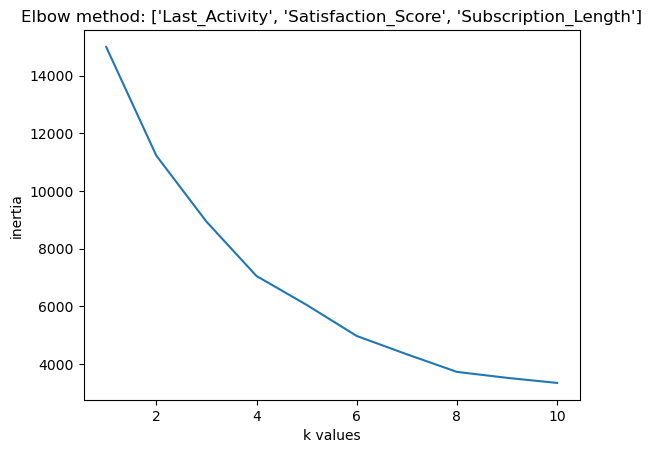

In [73]:
# Preprocess the features for groupe 2
clustering_exp.prepare_feature(grp_2)
# Determine the appropriate number of clusters (k)
clustering_exp.elbow_method()

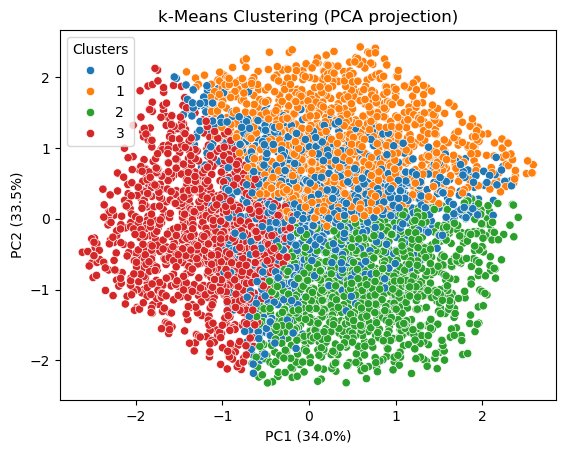

{'davies_bouldin_score': np.float64(1.0928380661476296),
 'silhouette_score': np.float64(0.276419785034193)}

In [74]:
# Perform clustering with the appropriate number of clusters
clustering_exp.k_means(nb_clusters=4)

The features likely have continuous relationship. This explains the overlapping.

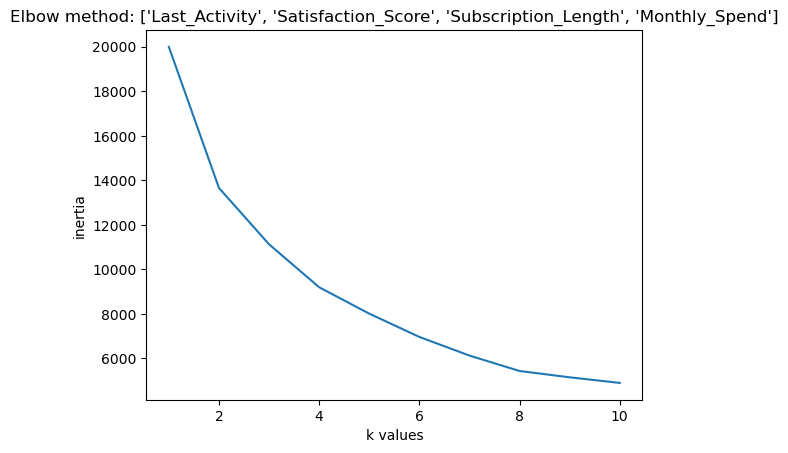

In [75]:
# Preprocess the features for group 3
clustering_exp.prepare_feature(grp_3)
# Determine the appropriate number of clusters (k)
clustering_exp.elbow_method()

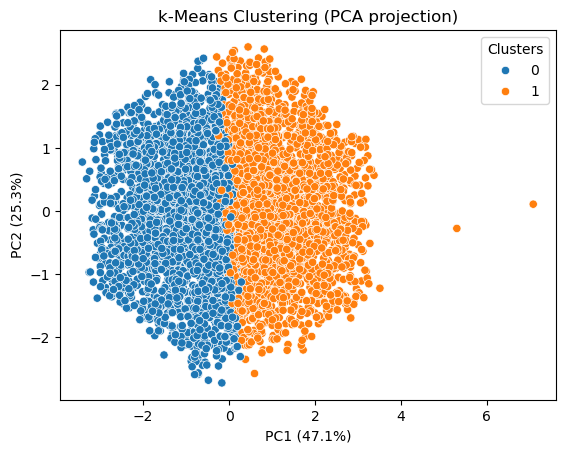

{'davies_bouldin_score': np.float64(1.3979996926938107),
 'silhouette_score': np.float64(0.2791608373890173)}

In [76]:
# Perform clustering with the appropriate number of clusters
clustering_exp.k_means(nb_clusters=2)

We notice an interesting separation along PC1 and PC1 explains a large proportion of variance (47%). This shows that the dominant source of variation in the data is along PC1. By adding monthly_spend to the previous group, the clustering structure reduces to 2 clusters. Monthly spend likely play a major role in the variance structure. So the two clusters could be interpreted as lower vs higher spending customers.

The most distinct clusters were obtained when including categorical context (Region), suggesting satisfaction differs by region. Purely numerical pairs produced weaker, more continuous structure.

Overall, the clearest clustering was obtained with Region vs Satisfaction Score (highest silhouette and low Davies–Bouldin), indicating that categorical context contributes most to separable segments, whereas numerical-only feature pairs mainly showed continuous trends and weaker cluster structure.

In [77]:
pd.DataFrame(clustering_exp.results)

,"kmeans: ['Age', 'Gender', 'Region']","kmeans: ['Last_Activity', 'Satisfaction_Score', 'Subscription_Length']","kmeans: ['Last_Activity', 'Satisfaction_Score', 'Subscription_Length', 'Monthly_Spend']"
davies_bouldin_score,1.273159,1.092838,1.398000
silhouette_score,0.382788,0.276420,0.279161


#### Clustering with Hierarchical

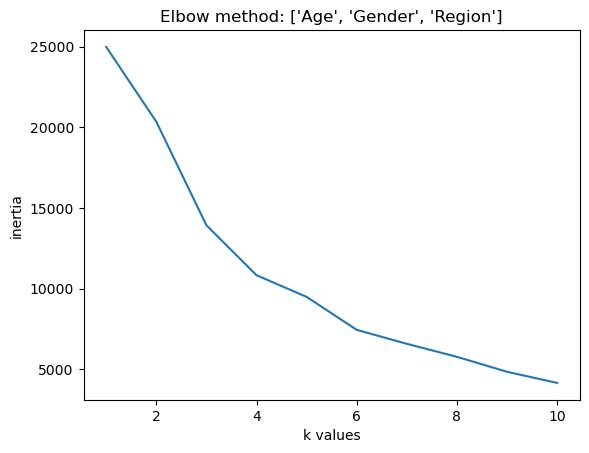

In [78]:
# Preprocess the features for groupe 1
clustering_exp.prepare_feature(grp_1)

# Determine the appropriate number of clusters (k)
clustering_exp.elbow_method()

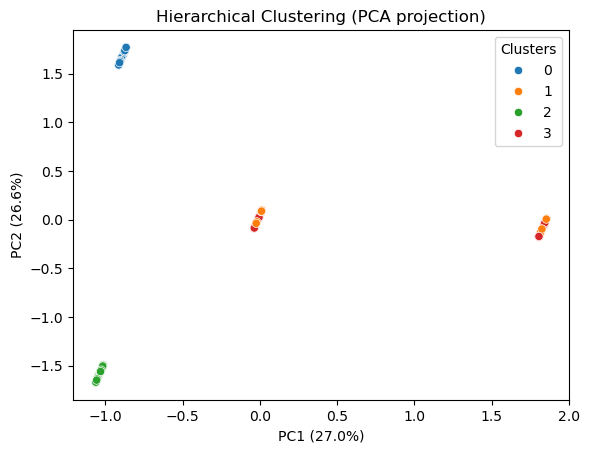

{'davies_bouldin_score': np.float64(1.4883806696689834),
 'silhouette_score': np.float64(0.3385406605432162)}

In [79]:
# Perform clustering with the appropriate number of clusters
clustering_exp.hierarchical_clustering(nb_clusters=4)

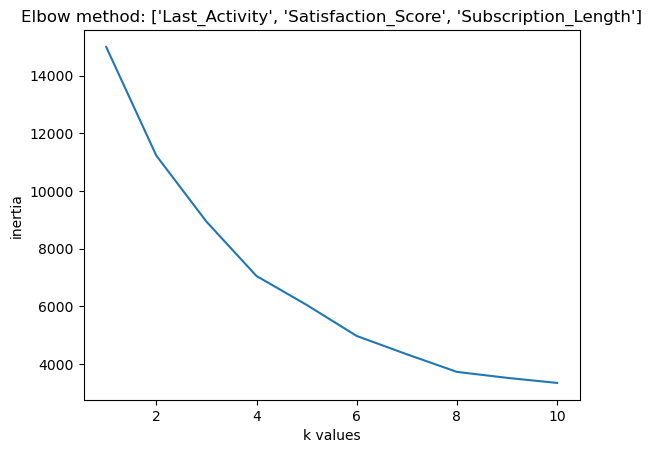

In [80]:
# Preprocess the features for groupe 2
clustering_exp.prepare_feature(grp_2)

# Determine the appropriate number of clusters (k)
clustering_exp.elbow_method()

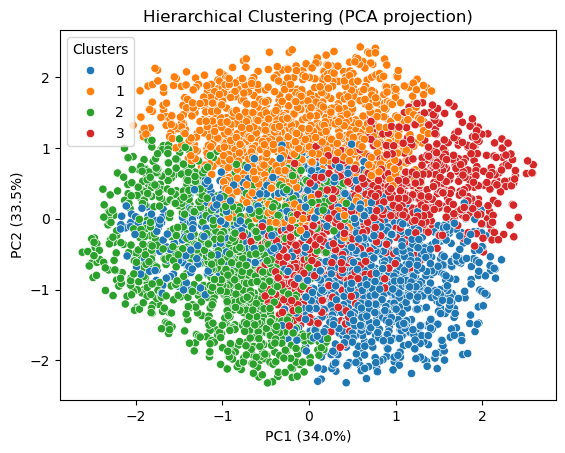

{'davies_bouldin_score': np.float64(1.5060174252570968),
 'silhouette_score': np.float64(0.17108870011766147)}

In [81]:
# Perform clustering with the appropriate number of clusters
clustering_exp.hierarchical_clustering(nb_clusters=4)

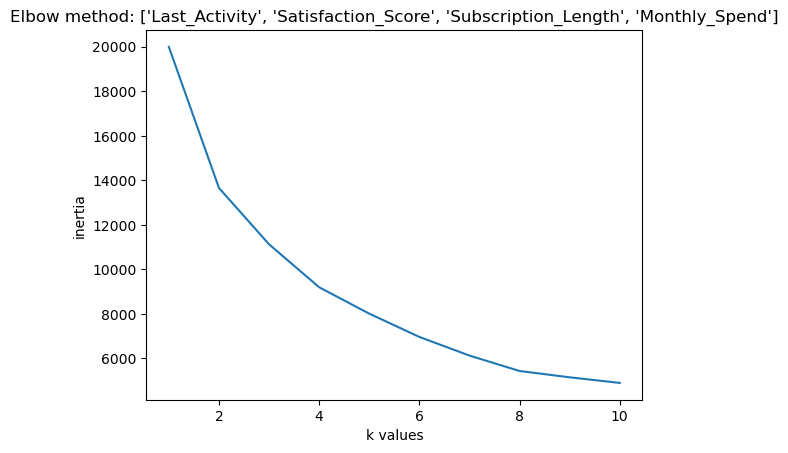

In [82]:
# Preprocess the features for groupe 3
clustering_exp.prepare_feature(grp_3)

# Determine the appropriate number of clusters (k)
clustering_exp.elbow_method()

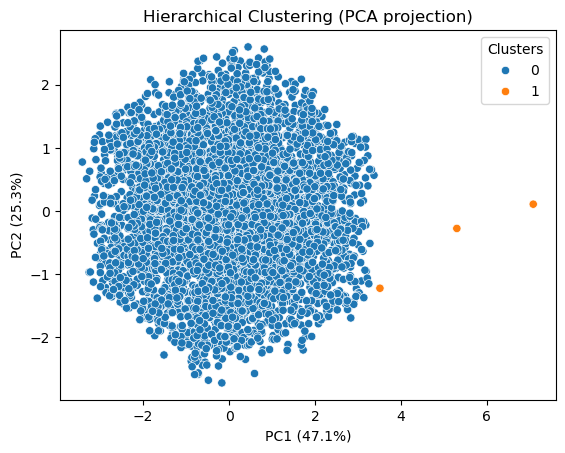

{'davies_bouldin_score': np.float64(0.5134870653183998),
 'silhouette_score': np.float64(0.6632674380651881)}

In [85]:
# Perform clustering with the appropriate number of clusters
clustering_exp.hierarchical_clustering(nb_clusters=2)

In [86]:
pd.DataFrame(clustering_exp.results)

,"kmeans: ['Age', 'Gender', 'Region']","kmeans: ['Last_Activity', 'Satisfaction_Score', 'Subscription_Length']","kmeans: ['Last_Activity', 'Satisfaction_Score', 'Subscription_Length', 'Monthly_Spend']","hierarchical_['Age', 'Gender', 'Region']","hierarchical_['Last_Activity', 'Satisfaction_Score', 'Subscription_Length']","hierarchical_['Last_Activity', 'Satisfaction_Score', 'Subscription_Length', 'Monthly_Spend']"
davies_bouldin_score,1.273159,1.092838,1.398000,1.488381,1.506017,0.513487
silhouette_score,0.382788,0.276420,0.279161,0.338541,0.171089,0.663267


Almost all points are in one cluster and the second one is formed by outliers. Although the metrics look excellent, this is not a meaningful segmentation. 